# THỰC HÀNH CLASSIFICATION VỚI DỮ LIỆU BẢNG — TUẦN 3
## Breast Cancer Wisconsin và Wine Quality
Quy ước lớp: 0 = Benign, 1 = Malignant (lớp dương). Quy trình theo notebook giảng viên: split trước, sampling trong train fold, chọn theo CV trên Train, Test chỉ đánh giá sau cùng.

# PHẦN 1. BREAST CANCER — BÀI 1
## Bước 1. Import, nạp dữ liệu, đổi mã nhãn và tạo tập imbalance

In [1]:
import sys,warnings,os
os.environ.setdefault('LOKY_MAX_CPU_COUNT','1')
warnings.filterwarnings('ignore')
import numpy as np,pandas as pd,matplotlib.pyplot as plt,sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split,KFold,StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,average_precision_score,classification_report,ConfusionMatrixDisplay
from pathlib import Path
SEED=42
bc=load_breast_cancer(as_frame=True);Xall=bc.data;yall=(bc.target==0).astype(int)
print('Python',sys.version.split()[0],'sklearn',sklearn.__version__,'shape',Xall.shape,'benign',int((yall==0).sum()),'malignant',int(yall.sum()))
def variant(n):
 pos=np.flatnonzero(np.asarray(yall)==1);neg=np.flatnonzero(np.asarray(yall)==0)
 take=pos if n is None else np.random.default_rng(SEED+n).choice(pos,n,replace=False)
 ix=np.r_[neg,take];np.random.default_rng(SEED).shuffle(ix)
 return Xall.iloc[ix].reset_index(drop=True),pd.Series(np.asarray(yall)[ix])
def scores(y,p):
 z=(p>=.5).astype(int)
 return {'Accuracy':accuracy_score(y,z),'Precision':precision_score(y,z,zero_division=0),'Recall':recall_score(y,z,zero_division=0),'F1':f1_score(y,z,zero_division=0),'PR-AUC':average_precision_score(y,p)}

Python 3.12.14 sklearn 1.7.2 shape (569, 30) benign 357 malignant 212


## Bài 1. Mức độ imbalance
Giữ toàn bộ Benign, lấy lần lượt 40, 120 và toàn bộ Malignant. Tính Accuracy, Recall, F1, PR-AUC trên Test stratified.

,Malignant Test,Accuracy,Recall,F1,PR-AUC
Dữ liệu,,,,,
40 malignant,8,1.0000,1.0000,1.0000,1.0000
120 malignant,24,0.9896,0.9583,0.9787,0.9940
Toàn bộ dữ liệu,42,0.9737,0.9762,0.9647,0.9984


                 Malignant Test  Accuracy  Recall      F1  PR-AUC
Dữ liệu                                                          
40 malignant                  8    1.0000  1.0000  1.0000  1.0000
120 malignant                24    0.9896  0.9583  0.9787  0.9940
Toàn bộ dữ liệu              42    0.9737  0.9762  0.9647  0.9984

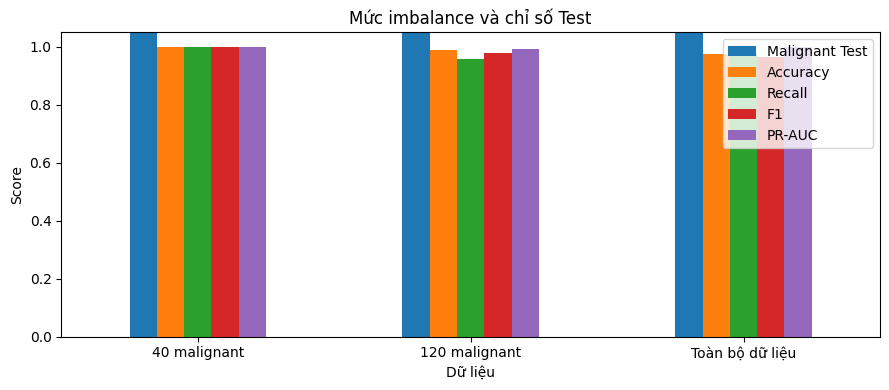

In [2]:
imb=[]
for label,n in [('40 malignant',40),('120 malignant',120),('Toàn bộ dữ liệu',None)]:
 Xv,yv=variant(n);a,b,c,d=train_test_split(Xv,yv,test_size=.2,random_state=SEED,stratify=yv)
 model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=4000,random_state=SEED)).fit(a,c)
 q=scores(d,model.predict_proba(b)[:,1]);imb.append({'Dữ liệu':label,'Malignant Test':int(d.sum()),**{k:q[k] for k in ['Accuracy','Recall','F1','PR-AUC']}})
imbalance=pd.DataFrame(imb).set_index('Dữ liệu');display(imbalance.round(4))
imbalance.plot(kind='bar',figsize=(9,4),ylim=(0,1.05),title='Mức imbalance và chỉ số Test');plt.ylabel('Score');plt.xticks(rotation=0);plt.tight_layout();plt.show()
X60,y60=variant(60);Xtr,Xte,ytr,yte=train_test_split(X60,y60,test_size=.2,random_state=SEED,stratify=y60)
fixed=list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(Xtr,ytr))

## Bước 2. Hàm CV với scale và sampling chỉ trên train fold
Các phép ROS, RUS và SMOTE được cài đặt bằng NumPy/NearestNeighbors vì imbalanced-learn không có trong môi trường chạy. Scaler được fit trên train fold; dữ liệu validation không bị sampling.

In [3]:
def resample(A,y,method='none',ratio=1.,seed=42):
 A=np.asarray(A);y=np.asarray(y);rng=np.random.default_rng(seed)
 cls,n=np.unique(y,return_counts=True);lo,hi=cls[np.argmin(n)],cls[np.argmax(n)];nlo,nhi=n.min(),n.max()
 if method=='none':return A,y
 desired=min(nhi,int(np.ceil(ratio*nhi)))
 if method=='over':
  ix=np.flatnonzero(y==lo);extra=rng.choice(ix,max(0,desired-nlo),replace=True);ids=np.r_[np.arange(len(y)),extra];return A[ids],y[ids]
 if method=='under':
  il=np.flatnonzero(y==lo);ih=np.flatnonzero(y==hi);keep=max(nlo,int(nlo/ratio));ids=np.r_[il,rng.choice(ih,min(keep,len(ih)),replace=False)];rng.shuffle(ids);return A[ids],y[ids]
 if method=='smote':
  from sklearn.neighbors import NearestNeighbors
  minority=A[y==lo];need=max(0,desired-nlo);k=min(5,len(minority)-1)
  if need==0:return A,y
  near=NearestNeighbors(n_neighbors=k+1).fit(minority).kneighbors(return_distance=False)[:,1:]
  base=rng.integers(len(minority),size=need);other=near[base,rng.integers(k,size=need)]
  syn=minority[base]+rng.random((need,1))*(minority[other]-minority[base])
  return np.vstack((A,syn)),np.r_[y,np.full(need,lo,dtype=y.dtype)]
def cvrun(X,y,splits,method='none',ratio=1.,kind='logistic',scale=True):
 X=np.asarray(X);y=np.asarray(y);out=[]
 for f,(tr,va) in enumerate(splits):
  sc=StandardScaler() if scale else None;A=sc.fit_transform(X[tr]) if sc else X[tr];B=sc.transform(X[va]) if sc else X[va]
  A,yy=resample(A,y[tr],method,ratio,SEED+f)
  est={'logistic':LogisticRegression(max_iter=4000,random_state=SEED),'knn':KNeighborsClassifier(5),'svm':SVC(probability=True,random_state=SEED),'tree':DecisionTreeClassifier(max_depth=5,random_state=SEED)}[kind]
  est.fit(A,yy);out.append(scores(y[va],est.predict_proba(B)[:,1]))
 return pd.DataFrame(out)

## Bài 2. KFold và StratifiedKFold
Cùng Logistic Regression, cùng Train và cùng số fold. Báo cáo mean và population standard deviation.

In [4]:
fr=[]
for name,cv in [('KFold',KFold(5,shuffle=True,random_state=SEED)),('StratifiedKFold',StratifiedKFold(5,shuffle=True,random_state=SEED))]:
 z=cvrun(Xtr,ytr,list(cv.split(Xtr,ytr)))
 for metric in z:fr.append({'CV':name,'Metric':metric,'Mean':z[metric].mean(),'Std':z[metric].std(ddof=0)})
display(pd.DataFrame(fr).pivot(index='Metric',columns='CV',values=['Mean','Std']).round(4))

Mean 
 Std 
 
 
 CV 
 KFold 
 StratifiedKFold 
 KFold 
 StratifiedKFold 
 
 
 Metric 
 
 
 
 
 
 
 
 
 Accuracy 
 0.9821 
 0.9850 
 0.0174 
 0.0135 
 
 
 F1 
 0.9227 
 0.9423 
 0.0786 
 0.0530 
 
 
 PR-AUC 
 0.9759 
 0.9809 
 0.0312 
 0.0195 
 
 
 Precision 
 1.0000 
 1.0000 
 0.0000 
 0.0000 
 
 
 Recall 
 0.8662 
 0.8956 
 0.1335 
 0.0947

             Mean                     Std                
CV          KFold StratifiedKFold   KFold StratifiedKFold
Metric                                                   
Accuracy   0.9821          0.9850  0.0174          0.0135
F1         0.9227          0.9423  0.0786          0.0530
PR-AUC     0.9759          0.9809  0.0312          0.0195
Precision  1.0000          1.0000  0.0000          0.0000
Recall     0.8662          0.8956  0.1335          0.0947

## Bài 3. Thay đổi K = 3, 5, 10

In [5]:
kr=[]
for k in [3,5,10]:
 z=cvrun(Xtr,ytr,list(StratifiedKFold(k,shuffle=True,random_state=SEED).split(Xtr,ytr)))
 for metric in z:kr.append({'K':k,'Metric':metric,'Mean':z[metric].mean(),'Std':z[metric].std(ddof=0)})
display(pd.DataFrame(kr).pivot(index='Metric',columns='K',values=['Mean','Std']).round(4))

Mean 
 Std 
 
 
 K 
 3 
 5 
 10 
 3 
 5 
 10 
 
 
 Metric 
 
 
 
 
 
 
 
 
 
 
 Accuracy 
 0.9850 
 0.9850 
 0.9849 
 0.0042 
 0.0135 
 0.0151 
 
 
 F1 
 0.9448 
 0.9423 
 0.9413 
 0.0162 
 0.0530 
 0.0594 
 
 
 PR-AUC 
 0.9811 
 0.9809 
 0.9842 
 0.0085 
 0.0195 
 0.0259 
 
 
 Precision 
 1.0000 
 1.0000 
 1.0000 
 0.0000 
 0.0000 
 0.0000 
 
 
 Recall 
 0.8958 
 0.8956 
 0.8950 
 0.0295 
 0.0947 
 0.1059

             Mean                     Std                
K              3       5       10      3       5       10
Metric                                                   
Accuracy   0.9850  0.9850  0.9849  0.0042  0.0135  0.0151
F1         0.9448  0.9423  0.9413  0.0162  0.0530  0.0594
PR-AUC     0.9811  0.9809  0.9842  0.0085  0.0195  0.0259
Precision  1.0000  1.0000  1.0000  0.0000  0.0000  0.0000
Recall     0.8958  0.8956  0.8950  0.0295  0.0947  0.1059

## Bài 4. Over-Sampling strategy = 0.5, 0.75, 1.0

,Accuracy,Precision,Recall,F1,PR-AUC
sampling_strategy,,,,,
0.50,0.985,0.9800,0.9178,0.9460,0.9816
0.75,0.985,0.9800,0.9178,0.9460,0.9836
1.00,0.982,0.9538,0.9378,0.9399,0.9791


                   Accuracy  Precision  Recall      F1  PR-AUC
sampling_strategy                                             
0.50                  0.985     0.9800  0.9178  0.9460  0.9816
0.75                  0.985     0.9800  0.9178  0.9460  0.9836
1.00                  0.982     0.9538  0.9378  0.9399  0.9791

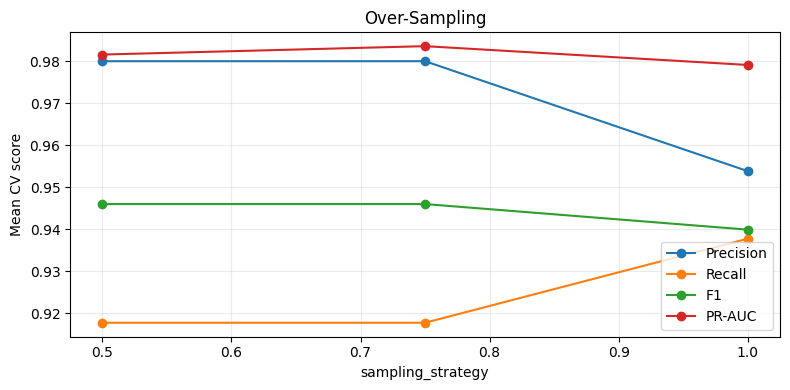

In [6]:
rr=[]
for r in [.5,.75,1.]:
 z=cvrun(Xtr,ytr,fixed,'over',r);rr.append({'sampling_strategy':r,**z.mean().to_dict()})
over_results=pd.DataFrame(rr).set_index('sampling_strategy');display(over_results.round(4))
over_results[['Precision','Recall','F1','PR-AUC']].plot(marker='o',figsize=(8,4),title='Over-Sampling');plt.ylabel('Mean CV score');plt.grid(alpha=.25);plt.tight_layout();plt.show()

## Bài 5. ROS, RUS và SMOTE
Dùng cùng các fold StratifiedKFold.

,Accuracy,Precision,Recall,F1,PR-AUC
Sampling,,,,,
over,0.9820,0.9538,0.9378,0.9399,0.9791
under,0.9701,0.8705,0.9578,0.9076,0.9751
smote,0.9850,0.9667,0.9378,0.9478,0.9875


          Accuracy  Precision  Recall      F1  PR-AUC
Sampling                                             
over        0.9820     0.9538  0.9378  0.9399  0.9791
under       0.9701     0.8705  0.9578  0.9076  0.9751
smote       0.9850     0.9667  0.9378  0.9478  0.9875

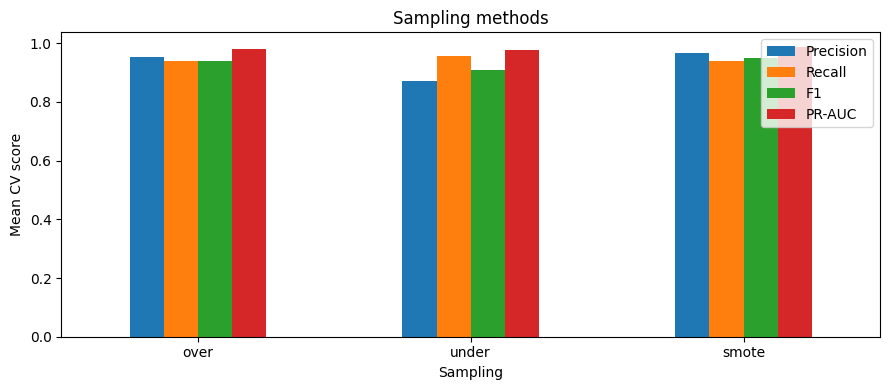

In [7]:
sr=[]
for method in ['over','under','smote']:
 z=cvrun(Xtr,ytr,fixed,method,1.);sr.append({'Sampling':method,**z.mean().to_dict()})
sampling_results=pd.DataFrame(sr).set_index('Sampling');display(sampling_results.round(4))
sampling_results[['Precision','Recall','F1','PR-AUC']].plot(kind='bar',figsize=(9,4),title='Sampling methods');plt.ylabel('Mean CV score');plt.xticks(rotation=0);plt.tight_layout();plt.show()

## Bài 6. Thay classifier và ảnh hưởng StandardScaler
Dùng ROS và cùng fold; so sánh Logistic Regression, KNN, SVM, Decision Tree với/không StandardScaler.

In [8]:
cr=[]
for label,kind in [('Logistic Regression','logistic'),('KNN','knn'),('SVM','svm'),('Decision Tree','tree')]:
 for scale in [True,False]:
  z=cvrun(Xtr,ytr,fixed,'over',1.,kind,scale)
  cr.append({'Classifier':label,'StandardScaler':scale,'Precision':z.Precision.mean(),'Recall':z.Recall.mean(),'F1':z.F1.mean(),'PR-AUC':z['PR-AUC'].mean()})
classifier_results=pd.DataFrame(cr);display(classifier_results.round(4))

,Classifier,StandardScaler,Precision,Recall,F1,PR-AUC
0,Logistic Regression,True,0.9538,0.9378,0.9399,0.9791
1,Logistic Regression,False,0.8132,0.9133,0.8553,0.9522
2,KNN,True,0.8903,0.8956,0.8882,0.9055
3,KNN,False,0.7031,0.8133,0.7398,0.7490
4,SVM,True,0.9303,0.8956,0.9075,0.9787
5,SVM,False,0.6163,0.8533,0.7095,0.8842
6,Decision Tree,True,0.8192,0.8356,0.8260,0.7264
7,Decision Tree,False,0.8192,0.8356,0.8260,0.7264


            Classifier  StandardScaler  Precision  Recall      F1  PR-AUC
0  Logistic Regression            True     0.9538  0.9378  0.9399  0.9791
1  Logistic Regression           False     0.8132  0.9133  0.8553  0.9522
2                  KNN            True     0.8903  0.8956  0.8882  0.9055
3                  KNN           False     0.7031  0.8133  0.7398  0.7490
4                  SVM            True     0.9303  0.8956  0.9075  0.9787
5                  SVM           False     0.6163  0.8533  0.7095  0.8842
6        Decision Tree            True     0.8192  0.8356  0.8260  0.7264
7        Decision Tree           False     0.8192  0.8356  0.8260  0.7264

### Bài 7. Trả lời 8 câu hỏi
1. Không sampling Test để giữ phân bố tự nhiên và phép đo cuối độc lập.
2. Không fit scaler trên toàn bộ dữ liệu vì thống kê Test sẽ rò vào huấn luyện; fit trong train fold.
3. Recall quan trọng hơn khi bỏ sót ca dương có hậu quả cao.
4. Precision quan trọng hơn khi dương giả gây chi phí hoặc can thiệp không cần thiết.
5. PR-AUC tập trung vào Precision/Recall lớp dương, hữu ích khi lớp dương hiếm.
6. StratifiedKFold giữ tỷ lệ lớp gần nhau và tránh fold thiếu minority.
7. RUS có thể xóa các mẫu majority quan trọng, nhất là vùng biên.
8. ROS lặp mẫu thiệt; SMOTE nội suy mẫu mới giữa các minority lân cận.

## Bước 3. Chọn bằng CV và đánh giá Test
Chọn chiến lược có F1 CV cao nhất trên Train, fit lại và chỉ sau đó đánh giá Test.

Chọn bằng CV: smote
               precision    recall  f1-score   support

   Benign (0)     1.0000    1.0000    1.0000        72
Malignant (1)     1.0000    1.0000    1.0000        12

     accuracy                         1.0000        84
    macro avg     1.0000    1.0000    1.0000        84
 weighted avg     1.0000    1.0000    1.0000        84



,Sampling,F1 CV
3,smote,0.9478
0,none,0.9423
1,over,0.9399
2,under,0.9076


  Sampling   F1 CV
3    smote  0.9478
0     none  0.9423
1     over  0.9399
2    under  0.9076

,Test
Accuracy,1.0
Precision,1.0
Recall,1.0
F1,1.0
PR-AUC,1.0


           Test
Accuracy    1.0
Precision   1.0
Recall      1.0
F1          1.0
PR-AUC      1.0

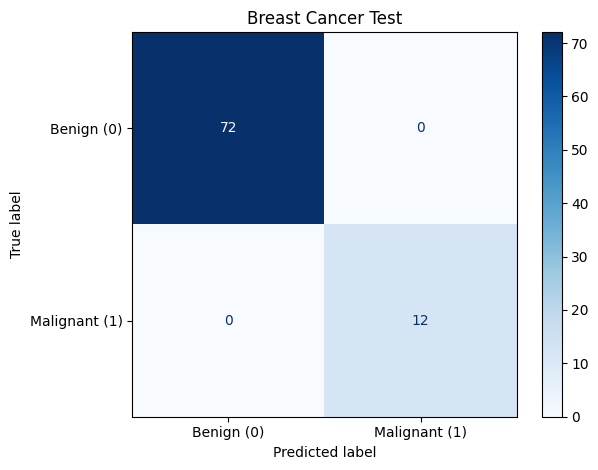

In [9]:
cand=[]
for method in ['none','over','under','smote']:
 z=cvrun(Xtr,ytr,fixed,method,1.);cand.append({'Sampling':method,'F1 CV':z.F1.mean()})
cand=pd.DataFrame(cand).sort_values('F1 CV',ascending=False);display(cand.round(4))
best=cand.iloc[0]['Sampling'];sc=StandardScaler().fit(Xtr);A=sc.transform(Xtr);B=sc.transform(Xte);A,yy=resample(A,ytr,best,1.,SEED)
final=LogisticRegression(max_iter=4000,random_state=SEED).fit(A,yy);prob=final.predict_proba(B)[:,1];pred=(prob>=.5).astype(int)
print('Chọn bằng CV:',best);display(pd.Series(scores(yte,prob),name='Test').to_frame().round(4))
ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=['Benign (0)','Malignant (1)'],cmap='Blues');plt.title('Breast Cancer Test');plt.tight_layout();plt.show()
print(classification_report(yte,pred,target_names=['Benign (0)','Malignant (1)'],digits=4,zero_division=0))

# PHẦN 2. BÀI 2 — WINE QUALITY MERGED
## Bước 1. Kiểm tra tệp, kiểu, missing, duplicate và nhãn
Dùng quality làm nhãn đa lớp vì đây là trường điểm chất lượng rời rạc; type mô tả đỏ/trắng và được mã hóa như đặc trưng. Không gộp nhãn.

In [10]:
root=Path.cwd();paths=[root/'Data'/'Buổi 3 (1)'/'wine_quality_merged.csv',root.parent/'Data'/'Buổi 3 (1)'/'wine_quality_merged.csv'];wine_path=next((p for p in paths if p.exists()),None)
if wine_path is None:print('Không tìm thấy wine_quality_merged.csv; cập nhật đường dẫn trong cell này khi bổ sung dữ liệu.')
else:
 wine=pd.read_csv(wine_path);print('Path:',wine_path,'shape:',wine.shape);display(wine.head())
 display(pd.DataFrame({'dtype':wine.dtypes.astype(str),'missing':wine.isna().sum(),'unique':wine.nunique()}));print('duplicates:',int(wine.duplicated().sum()))
 print('quality classes:',sorted(wine.quality.dropna().unique()));display(wine.quality.value_counts().sort_index().to_frame('count'))

Path: C:\Users\Nitro\Documents\THXDMHTTNT\Data\Buổi 3 (1)\wine_quality_merged.csv shape: (6497, 13)
duplicates: 1177
quality classes: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


   fixed acidity  volatile acidity  citric acid  ...  alcohol  quality  type
0            7.4              0.70         0.00  ...      9.4        5   red
1            7.8              0.88         0.00  ...      9.8        5   red
2            7.8              0.76         0.04  ...      9.8        5   red
3           11.2              0.28         0.56  ...      9.8        6   red
4            7.4              0.70         0.00  ...      9.4        5   red

[5 rows x 13 columns]

,dtype,missing,unique
fixed acidity,float64,0,106
volatile acidity,float64,0,187
citric acid,float64,0,89
residual sugar,float64,0,316
chlorides,float64,0,214
free sulfur dioxide,float64,0,135
total sulfur dioxide,float64,0,276
density,float64,0,998
pH,float64,0,108
sulphates,float64,0,111


                        dtype  missing  unique
fixed acidity         float64        0     106
volatile acidity      float64        0     187
citric acid           float64        0      89
residual sugar        float64        0     316
chlorides             float64        0     214
free sulfur dioxide   float64        0     135
total sulfur dioxide  float64        0     276
density               float64        0     998
pH                    float64        0     108
sulphates             float64        0     111
alcohol               float64        0     111
quality                 int64        0       7
type                   object        0       2

,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


         count
quality       
3           30
4          216
5         2138
6         2836
7         1079
8          193
9            5

## Bước 2. Pipeline tiền xử lý, Cross Validation, Classification Report và Confusion Matrix

CV winner: Random Forest Test accuracy: 0.6862 macro-F1: 0.3704
              precision    recall  f1-score   support

           3     0.0000    0.0000    0.0000         6
           4     0.5000    0.0465    0.0851        43
           5     0.7330    0.7056    0.7190       428
           6     0.6522    0.7972    0.7175       567
           7     0.6944    0.5787    0.6313       216
           8     1.0000    0.2821    0.4400        39
           9     0.0000    0.0000    0.0000         1

    accuracy                         0.6862      1300
   macro avg     0.5114    0.3443    0.3704      1300
weighted avg     0.6877    0.6862    0.6706      1300



,Accuracy CV,Macro-F1 CV,Weighted-F1 CV
Model,,,
Random Forest,0.6575,0.3581,0.6391
HistGradientBoosting,0.6119,0.3497,0.6031
Logistic Regression,0.5440,0.2390,0.5117


                      Accuracy CV  Macro-F1 CV  Weighted-F1 CV
Model                                                         
Random Forest              0.6575       0.3581          0.6391
HistGradientBoosting       0.6119       0.3497          0.6031
Logistic Regression        0.5440       0.2390          0.5117

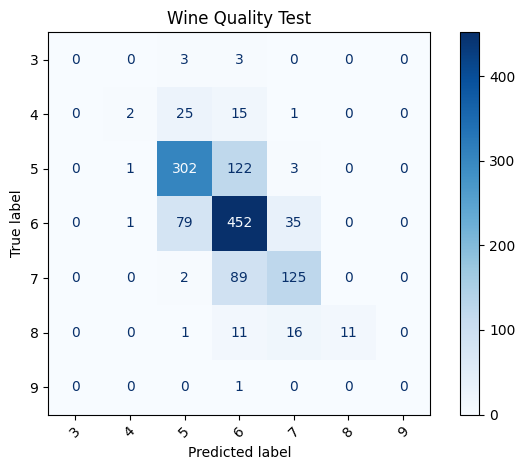

In [11]:
if wine_path is not None:
 from sklearn.compose import ColumnTransformer
 from sklearn.preprocessing import OneHotEncoder
 from sklearn.impute import SimpleImputer
 from sklearn.pipeline import Pipeline
 from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
 from sklearn.model_selection import cross_validate
 from sklearn.metrics import f1_score
 data=wine.dropna(subset=['quality']).copy();yw=data.quality.astype(int);Xw=data.drop(columns='quality')
 num=Xw.select_dtypes(include=np.number).columns.tolist();cat=Xw.select_dtypes(exclude=np.number).columns.tolist()
 prep=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)])
 Xt,Xv,yt,yv=train_test_split(Xw,yw,test_size=.2,random_state=SEED,stratify=yw)
 models={'Logistic Regression':LogisticRegression(max_iter=3000),'Random Forest':RandomForestClassifier(n_estimators=140,min_samples_leaf=2,random_state=SEED,n_jobs=1),'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=100,random_state=SEED)}
 res=[];pipes={};cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
 for name,est in models.items():
  pipe=Pipeline([('preprocess',prep),('model',est)])
  z=cross_validate(pipe,Xt,yt,cv=cv,scoring={'accuracy':'accuracy','macro_f1':'f1_macro','weighted_f1':'f1_weighted'},n_jobs=1)
  res.append({'Model':name,'Accuracy CV':z['test_accuracy'].mean(),'Macro-F1 CV':z['test_macro_f1'].mean(),'Weighted-F1 CV':z['test_weighted_f1'].mean()});pipes[name]=pipe
 wine_results=pd.DataFrame(res).set_index('Model').sort_values('Macro-F1 CV',ascending=False);display(wine_results.round(4))
 winner=wine_results.index[0];pipes[winner].fit(Xt,yt);p=pipes[winner].predict(Xv)
 print('CV winner:',winner,'Test accuracy:',round(accuracy_score(yv,p),4),'macro-F1:',round(f1_score(yv,p,average='macro'),4))
 print(classification_report(yv,p,digits=4,zero_division=0))
 ConfusionMatrixDisplay.from_predictions(yv,p,xticks_rotation=45,cmap='Blues');plt.title('Wine Quality Test');plt.tight_layout();plt.show()

### Kết luận Tuần 3
Đã xây dựng các thí nghiệm theo bảy bài trong notebook giảng viên và bài Wine Quality theo slide. Mọi kết quả được sinh khi chạy; lớp Test không tham gia sampling hay chọn mô hình.

**Lưu ý khi diễn giải:** Test Breast Cancer của lần chạy này có 84 mẫu, trong đó chỉ 12 mẫu Malignant; dù chỉ số Test của chiến lược được chọn đạt 1.0, cỡ mẫu dương nhỏ khiến ước lượng chưa ổn định và không nên hiểu là bảo đảm hiệu năng ngoài mẫu.
